<h3> whether to remove duplicates or not ,added as an argument in prerocessing #####################

Methodological limitation: The current notebook fits CountVectorizer before the train–‎test split. Therefore, the test set influences the feature vocabulary. In addition, exact ‎duplicate rows are retained in the reported workflow.‎
These issues should be disclosed and corrected before treating the scores as reliable ‎estimates of generalization to unseen sequences.‎
A corrected workflow should split the data first and fit the vectorizer only on the training ‎data, preferably using a scikit-learn pipeline. It should also investigate duplicate and highly ‎similar sequences and prevent problematic overlap across the training and test sets where ‎feasible.‎


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle##
import joblib
import os
import random
from collections import Counter##########
##
import tensorflow as tf
from tensorflow.keras.utils import to_categorical #one hot encoding
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split,KFold,cross_val_score,StratifiedKFold,GridSearchCV,RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error,explained_variance_score,max_error,mean_absolute_percentage_error
from sklearn.metrics import accuracy_score, confusion_matrix,  precision_score, recall_score, f1_score,classification_report,roc_auc_score,roc_curve,auc
from sklearn.linear_model import LinearRegression,LogisticRegression,Ridge, Lasso, ElasticNet
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB,MultinomialNB
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
# !pip install xgboost
import xgboost as xgb
from xgboost import XGBClassifier
# from lightgbm import LGBMClassifier
# !pip install catboost
import catboost
from catboost import CatBoostClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.decomposition import PCA,TruncatedSVD,NMF
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
########
from sklearn.feature_extraction.text import CountVectorizer

## Human Data

In [2]:
# df=pd.read_csv(r'human_data.txt', delim_whitespace=True)
df=pd.read_table(r'human_data.txt')
print('displaying org. df')
display(df.head(10))
print(f'shape:{df.shape}') #shape:(4380, 2)
print('###############')
print(df.info()) # no nan values
print('null values:\n',df.isnull().sum()) #zero
print('###########')
print('distribution of class column:\n',df['class'].value_counts())##
# df=df.dropna(subset='class') no nan values
####
#####################
df['sequence']=df['sequence'].str.strip() #make sure there is no interspaces(tab('\t'),enter('\n')) or space(' ')
df['sequence']=df['sequence'].str.upper()#make sure all bases are upper cased

displaying org. df


,sequence,class
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3
5,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
6,ATGAAGATTGCACACAGAGGTCCAGATGCATTCCGTTTTGAGAATG...,3
7,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3
8,ATGAAGATTGCACACAGAGGTCCAGATGCATTCCGTTTTGAGAATG...,3
9,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3


shape:(4380, 2)
###############
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4380 entries, 0 to 4379
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  4380 non-null   object
 1   class     4380 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 68.6+ KB
None
null values:
 sequence    0
class       0
dtype: int64
###########
distribution of class column:
 class
6    1343
4     711
3     672
1     534
0     531
2     349
5     240
Name: count, dtype: int64


In [3]:
df.describe(include='all').T#as we have 2 columns:one categorical(object dtype),one numerical(int64)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sequence,4380,3629,ATGGGACCAGAGGCCCTGTCATCTTTACTGCTGCTGCTCTTGGTGG...,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,4380.0,NaN,NaN,NaN,3.504566,2.132134,0.0,2.0,4.0,6.0,6.0


<h3> whether to remove duplicates or not ,added as an argument in prerocessing #####################

In [4]:
 #removing duplicate rows or not
print('duplicates:',df.duplicated().sum()) #751
# df=df.drop_duplicates()#only drop rows with exact duplicates!,if u want to only drop duplicate sequences even of classes differ,use subset='sequence'
# print('duplicates now:',df.duplicated().sum()) # zero now
dup_rows=df[df.duplicated()] #df of the duplicated rows only
dup_rows['class'].value_counts(normalize=0).sort_index() #sort from zero to 6
############
# Original class distribution
original_counts = df['class'].value_counts().sort_index()

# Duplicate class distribution
duplicate_counts = df[df.duplicated()]['class'].value_counts().sort_index()

# Align both series to avoid key errors
duplicate_counts = duplicate_counts.reindex(original_counts.index, fill_value=0)

# Calculate % of duplicates
percent_duplicates = (duplicate_counts / original_counts * 100).round(2)

# Build summary DataFrame
summary_df = pd.DataFrame({
    'Total Samples': original_counts,#2columns of idx(classes) and the counts(original)
    'Duplicate Rows': duplicate_counts,
    '% Duplicates': percent_duplicates.astype(str)+'%'
})
display(summary_df)

duplicates: 751


,Total Samples,Duplicate Rows,% Duplicates
class,,,
0,531,85,16.01%
1,534,126,23.6%
2,349,58,16.62%
3,672,102,15.18%
4,711,121,17.02%
5,240,25,10.42%
6,1343,234,17.42%


<h3> classes counts (without removing duplicate rows)

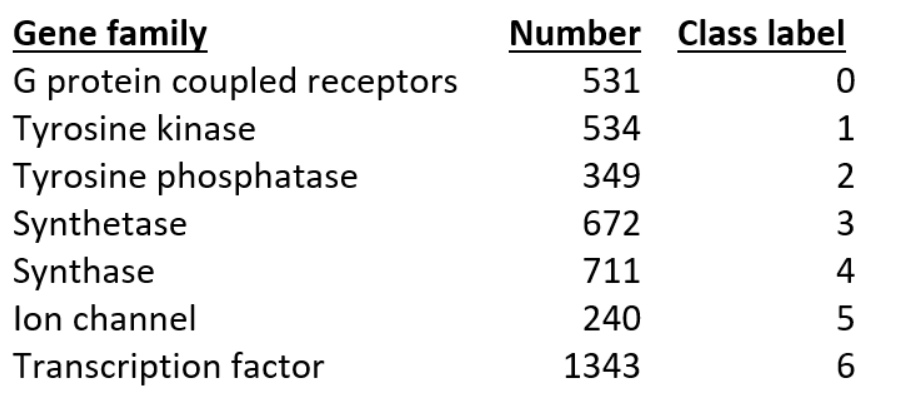

In [6]:
from IPython.display import Image
Image(filename="gene_family classes.png")#just pass the file name with its extension as it is in the same directory as the notebook
# display(Image(filename="Capture1.png", width=400, height=300))
#distribution

In [124]:
dir(counts)

['__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__reversed__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 'mapping']

In [8]:
# y.sort_values().unique()

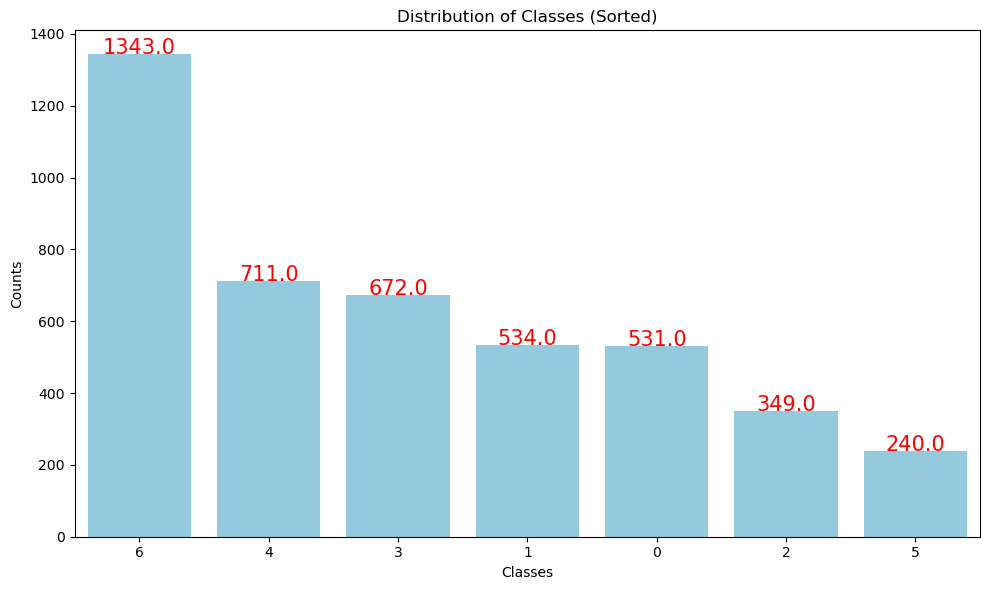

In [9]:
x=df.drop(columns=['class'])
###
y=df['class']#encoded(0,1,2,3,.. as int dtype)

# Count class frequencies
class_counts = Counter(y)

# Sort by count (descending)
#for item x(tuple) in the list, use its x[1] (second element) as the value to sort by.
sorted_items = sorted(class_counts.items(), key=lambda x: x[1], reverse=True) 
# Unpack sorted keys and values
classes, counts = zip(*sorted_items)
# Convert class labels to strings for correct Seaborn plotting as it will arrange them 0,1,2 if treated as numberical values
classes_str = list(map(str, classes))

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=classes_str, y=list(counts), color='skyblue')

# Add value labels
for cat, value in zip(classes_str, counts):
    plt.text(cat, value, f'{value:.1f}', ha='center', fontsize=15, color='red')

# Add labels and title
plt.xlabel('Classes')
plt.ylabel('Counts')
plt.title('Distribution of Classes (Sorted)')
plt.tight_layout()
plt.show()

In [10]:
sum(counts)

4380

### validation if all sequences of dna only include: ['A', 'C', 'T', 'G'] 
`but in the end we decided to not remove them so that the model isnt robust to different letters inputted`

In [32]:
valid_bases_set = set(['A', 'C', 'T', 'G'])#{'A','C','T','G'} #validation set
def validate_seq(sequence):#we made sure all sequences are upper cased just like the validation set
    return set(sequence).issubset(valid_bases_set) #sequence is each value(row) in the sequence column(column of sequences)
###
df_copy=df.copy()
df_copy['is_valid'] = df_copy['sequence'].apply(validate_seq)
df_copy['is_valid'].value_counts()

is_valid
True     3295
False     334
Name: count, dtype: int64

In [34]:
df_valid=df[df_copy['is_valid']==True]
display(df_valid.head(3))
print(f'displaying valid df')
print(df_valid.shape)
print('###########')
#####
df_not_valid=df[df_copy['is_valid']==False]
print(f'displaying non-valid df')
display(df_not_valid)
print(df_not_valid.shape)

,sequence,class
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3


displaying valid df
(3295, 2)
###########
displaying non-valid df


,sequence,class
34,NGGCAAACAAGAGAGAAAGCAAAATTTTCAGATGGAGAAAAGTGCC...,6
44,NTGCAGGTGATTTTCAAAGCCAAGTCAAAATATTCTCCAGAATTAC...,0
46,NNGTTAAACCTCAGCATCGGCGGCCCGGACTTCATGGATCATCCGT...,6
54,NGCCTCGCAGGCAGCACCAGCCTCATGCACAACCACGCGGCCCTCC...,6
59,NCCATGTCACTGGGCGGGCGGCACGCAGGCCTGGTTGGAGGCAGCC...,6
...,...,...
4211,NTGCGTAAGGGACACCCTTTGCTGGTAGCTGTCAAGATCTTACGGC...,1
4223,NNCTTGTGGATCACACTGAGCCTGCTGCAGACTGGACTGGCGGAGC...,2
4255,NTGGAGGGCGCGATGGCAGTGCGGGTGACGGCCGCTCATACGGCAG...,6
4266,NCCATCACCTTCTACCAGACACTGTGGGCCCGGCCCCGGAGGGCTC...,0


(334, 2)


<h3> in the rows of the invalid sequences they all start with N ,may be ambigous sequence of nucleotides

In [36]:
df_copy['sequence']=df_copy['sequence'].apply(lambda x:x.replace('N','')) #this is wrnog keep it so model might be familiar with gaps(N,X,....)
df_copy['is_valid_new']=df_copy['sequence'].apply(validate_seq)#apply the custom validation function again
print(df_copy['is_valid_new'].value_counts())#all true now
##
if (df_copy.shape[0]==(len(df_copy['is_valid_new']==True))):
    print('all sequences are valid now after removing the N part of each invalid sequence')
else:
    print('there is invalid sequences')
######
df_copy=df_copy.drop(columns=['is_valid','is_valid_new'])

is_valid_new
True    3629
Name: count, dtype: int64
all sequences are valid now after removing the N part of each invalid sequence


check for duplicated sequences

In [40]:
# print(df_copy.duplicated().sum())
# df_copy=df_copy.drop_duplicates()#only drop rows with exact duplicates!,if u want to only drop duplicate sequences even of classes differ,use subset='sequence'
# print(df_copy.duplicated().sum()) # zero now
###

display(df_copy) #cleaned df
# df_copy.to_csv('cleaned_dataframe',index=False) #if u desire so

,sequence,class
0,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTGTTCGCTTCATTCATTGCCCCCACAATCCTAG...,4
2,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
3,ATGTGTGGCATTTGGGCGCTGTTTGGCAGTGATGATTGCCTTTCTG...,3
4,ATGCAACAGCATTTTGAATTTGAATACCAGACCAAAGTGGATGGTG...,3
...,...,...
4275,ATGAATGACACAGTTAACAAAACAGATCAAGTGGACTGCAGCGACC...,6
4276,ATGAGCTCCTTCAAGCGGGGCTCGCTCAAGAGCTCCACATCAGGGT...,5
4277,ATGGGTCAGAAATCTTGGATAGAGAAAACCTTTTGCAAACGGGAAT...,5
4278,ACGAAAGACTCTAACAGGTGTTGCTGTGGCCAGTTCACCAACCAGC...,5


In [42]:
print(df_copy.shape)
df_copy.describe(include='all')

(3629, 2)


,sequence,class
count,3629,3629.000000
unique,3629,NaN
top,ATGCCCCAACTAAATACTACCGTATGGCCCACCATAATTACCCCCA...,NaN
freq,1,NaN
mean,NaN,3.524111
std,NaN,2.124251
min,NaN,0.000000
25%,NaN,2.000000
50%,NaN,4.000000
75%,NaN,6.000000


### preprocesing - human data

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4380 entries, 0 to 4379
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  4380 non-null   object
 1   class     4380 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 68.6+ KB


<h3> 1st we need to transforn the dna seq in a way that suits ML models>>>kmer

<h3> Treating DNA sequence as a "language", otherwise known as k-mer counting
<h3>A challenge that remains is that none of these above methods results in vectors of uniform length, and that is a requirement for feeding data to a classification or regression algorithm. So with the above <h3>methods you have to resort to things like truncating sequences or padding with "n" or "0" to get vectors of uniform length.

<h3>DNA and protein sequences can be viewed metaphorically as the language of life. The language encodes instructions as well as function for the molecules that are found in all life forms. The sequence <h3>language analogy continues with the genome as the book, subsequences (genes and gene families) are sentences and chapters, k-mers and peptides (motifs) are words, and nucleotide bases and amino acids are <h3>the alphabet. Since the analogy seems so apt, it stands to reason that the amazing work done in the natural language processing field should also apply to the natural language of DNA and protein sequences.

<h3>The method I use here is simple and easy. I first take the long biological sequence and break it down into k-mer length overlapping “words”. For example, if I use "words" of length 6 (hexamers), “ATGCATGCA” <h3>becomes: ‘ATGCAT’, ‘TGCATG’, ‘GCATGC’, ‘CATGCA’. Hence our example sequence is broken down into 4 hexamer words.

<h3>Here I am using hexamer “words” but that is arbitrary and word length can be tuned to suit the particular situation. The word length and amount of overlap need to be determined empirically for any given <h3>application.

<h3>In genomics, we refer to these types of manipulations as "k-mer counting", or counting the occurances of each possible k-mer sequence. There are specialized tools for this, but the Python natural language <h3>processing tools make it supe easy.

<h3>Here is a function that can be used to convert any sequence (string) to overlapping k-mer words:

| Reason                                 | Explanation                                                                                           |
| -------------------------------------- | ----------------------------------------------------------------------------------------------------- |
| 🔢 **Convert sequence to numbers**     | k-mer counts let you turn a DNA sequence into a feature vector (like Bag of Words in NLP).            |
| 🔍 **Capture biological patterns**     | Certain k-mers are over- or under-represented in disease, mutations, or species.                      |
| 🧠 **Input for ML models**             | ML models need numerical input — k-mer frequency vectors make this possible.                          |
| 🧬 **Species/Function classification** | Different organisms have distinct k-mer distributions. Useful in metagenomics, cancer subtyping, etc. |
| 🚀 **Efficient and scalable**          | k-mers allow efficient indexing, comparison, and storage of sequences in genomics pipelines.          |


In [12]:
# function to convert sequence strings into k-mer words, default size = 6 (hexamer words)
def getKmers(sequence, size=6): #hexamers
    return [sequence[x:x+size].lower() for x in range(len(sequence) - size + 1)]  #-size to stop k-steps from the last idx,and +1 as idx start from zero(range(n)~range(0,n-1)) n-1 +1=n

In [13]:
#add column of the k-mer transformed words and drop the original  sequence column
df['words']=df['sequence'].apply(lambda x:getKmers(x)) # x is each value(sequence ) in the sequence column
df=df.drop(columns='sequence')

In [14]:
display(df.head()) #changed to lowercase by kmer function

,class,words
0,4,"[atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac..."
1,4,"[atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa..."
2,3,"[atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca..."
3,3,"[atgtgt, tgtgtg, gtgtgg, tgtggc, gtggca, tggca..."
4,3,"[atgcaa, tgcaac, gcaaca, caacag, aacagc, acagc..."


<h3> Since we are going to use scikit-learn natural language processing tools to do the k-mer counting, we need to now convert the lists of k-mers for each gene into string sentences of words that the count vectorizer can use. We can also make a y variable to hold the class labels. Let's do that now

In [15]:
human_texts=list(df['words']) #this is a list of list(each list/item represent a row of kmers sequences)
for i in range(len(human_texts)):
    human_texts[i]=' '.join(human_texts[i]) #join the small kmer sequences of each row by a space ' '
y=df['class'] #0,1,2,3,4,5,6
print(human_texts[4])#this is the 4th list of the lists wrapped together that represent the 4th row

atgcaa tgcaac gcaaca caacag aacagc acagca cagcat agcatt gcattt catttt attttg ttttga tttgaa ttgaat tgaatt gaattt aatttg atttga tttgaa ttgaat tgaata gaatac aatacc atacca taccag accaga ccagac cagacc agacca gaccaa accaaa ccaaag caaagt aaagtg aagtgg agtgga gtggat tggatg ggatgg gatggt atggtg tggtga ggtgag gtgaga tgagat gagata agataa gataat ataatc taatcc aatcct atcctt tccttc ccttca cttcat ttcatc tcatct catctt atcttt tcttta ctttat tttatg ttatga tatgac atgaca tgacaa gacaaa acaaag caaagg aaagga aaggag aggagg ggagga gaggaa aggaat ggaatt gaattg aattga attgag ttgagc tgagca gagcaa agcaaa gcaaac caaaca aaacaa aacaat acaatt caattt aatttg atttgt tttgta ttgtat tgtatg gtatgt tatgtt atgttg tgttgg gttgga ttggat tggatg ggatgg gatggt atggtg tggtgt ggtgtg gtgtgt tgtgtt gtgttt tgtttg gtttgc tttgca ttgcat tgcatt gcattt catttg atttgt tttgtt ttgttt tgtttt gtttta ttttac tttact ttactg tactgg actgga ctggat tggata ggatac gatact atactg tactgc actgcc ctgcca tgccaa gccaat ccaata caataa aataag ataaga taagaa aagaaa agaaag

<h3>A n-gram is a sequence of n consecutive things (words, letters, whatever).
<h3>A k-mer is a sequence of k consecutive things (DNA basepairs).
<h3>The phrase k-mer is more common in computational genomics.
<h3>Creating the Bag of Words model using CountVectorizer()
<h3>`This is equivalent to k-mer counting`
<h3>`The n-gram size of 4 was previously determined by testing(gridserach cv / randomsearch cv)`
<h3>It is better that to use Gridsearchcv or RandomSearchcv(use this if on low spec model) for automating your hyperparameter which is alpha in case of MultinomialNB.
 
   ! https://stackoverflow.com/questions/33830959/multinomial-naive-bayes-parameter-alpha-setting-scikit-learn

### K-mers, CountVectorizer, and Machine Learning: How They Work Together

#### 1. K-mer extraction: breaking DNA into overlapping words

DNA contains four possible bases: A, T, C, and G. Instead of analyzing a long DNA sequence as one string, we divide it into shorter, overlapping pieces called **k-mers**.

In our project, `k = 6`, so each piece contains six nucleotides and is called a **hexamer**.

Example DNA sequence:

`ATGCGATCGTAC`

Its overlapping 6-mers are:

1. `ATGCGA`
2. `TGCGAT`
3. `GCGATC`
4. `CGATCG`
5. `GATCGT`
6. `ATCGTA`
7. `TCGTAC`

**Why do they overlap?** The window moves forward by one nucleotide each time, preserving local sequence patterns.

For example:
- First hexamer: `ATGCGA`
- Second hexamer: `TGCGAT`

The second drops the first nucleotide (`A`) and adds the next nucleotide (`T`). Five nucleotides are shared between consecutive hexamers.

The number of k-mers extracted from a sequence of length L is:

`Number of k-mers = L - k + 1`

For this 12-nucleotide sequence, `12 - 6 + 1 = 7` hexamers.

#### 2. CountVectorizer: turning sequence patterns into numerical features

A machine-learning model needs a numerical representation of the DNA sequences. We use `CountVectorizer` to convert the space-separated hexamers into numerical features.

Think of it as creating an inventory of patterns and counting their occurrences.

```python
cv = CountVectorizer(ngram_range=(4, 4))
x = cv.fit_transform(human_texts)
```

**What does `ngram_range=(min_n, max_n)` mean?**

- `min_n`: the minimum number of consecutive tokens grouped into a feature.
- `max_n`: the maximum number of consecutive tokens grouped into a feature.
- Both limits are inclusive. The vectorizer extracts every group size between them.

Here, each token is an existing 6-mer, not an individual nucleotide.

Examples:

- `(1, 1)`: groups of one token (individual hexamers).
- `(2, 2)`: groups of exactly two consecutive hexamers.
- `(1, 2)`: individual hexamers and pairs.
- `(2, 4)`: pairs, triples, and groups of four consecutive hexamers.
- `(4, 4)`: groups of exactly four consecutive hexamers.

With `(4, 4)`, the groups extracted from our example are:

1. `ATGCGA TGCGAT GCGATC CGATCG`
2. `TGCGAT GCGATC CGATCG GATCGT`
3. `GCGATC CGATCG GATCGT ATCGTA`
4. `CGATCG GATCGT ATCGTA TCGTAC`

These groups overlap because the original hexamers overlap. Four consecutive 6-mers collectively cover a nine-nucleotide window: the first contributes six nucleotides, and each of the next three adds one new nucleotide.

**Important distinction:**
- `k = 6` determines the length of each original DNA word.
- `ngram_range=(min_n, max_n)` determines how many consecutive hexamer tokens are grouped into each feature.

#### 3. How does CountVectorizer create the feature matrix?

Suppose the vectorizer discovers three distinct features in a small dataset:

| DNA sequence | Feature A | Feature B | Feature C |
|---|---:|---:|---:|
| Sequence 1 | 2 | 1 | 0 |
| Sequence 2 | 0 | 3 | 1 |

Each row represents one DNA sequence, each column represents one distinct feature, and each value indicates how many times that feature occurs.

- `fit`: learns which features exist in the training data.
- `transform`: converts sequences into counts using the learned vocabulary.
- `fit_transform`: performs both operations.
- `x.shape`: returns the number of sequences and the number of features.
- A sparse matrix stores nonzero counts efficiently without storing every zero.

For fair evaluation, fit the vectorizer on the training data and only transform the test data.

#### 4. Does CountVectorizer or Naive Bayes learn the biological patterns?

They have different jobs.

**Step 1 — K-mer function:** Extracts overlapping six-nucleotide words from DNA.

**Step 2 — CountVectorizer:** Organizes the tokens into features according to `ngram_range` and creates a numerical matrix of feature counts. It does not learn which patterns indicate which biological class.

**Step 3 — Machine-learning model:** Learns statistical relationships between numerical features and known class labels.

For example, if certain features occur frequently in training sequences belonging to a particular gene-associated class, the model may learn that those features support that class.

**Multinomial Naive Bayes** estimates how likely the observed features are under each class, using feature counts and class frequencies. It applies Bayes' theorem to estimate class probabilities and predict a class.

The model learns statistical associations, not necessarily the biological mechanism behind those patterns.

#### 5. The complete workflow

`DNA sequences`

→ **K-mer extraction:** split into overlapping 6-mers.

→ **CountVectorizer:** group tokens according to `ngram_range=(min_n, max_n)` and create numerical feature counts.

→ **Machine-learning model:** learn relationships between features and known class labels.

→ **Prediction:** assign an unseen sequence to a predicted class.

**In summary:** K-mer extraction creates the sequence words, CountVectorizer converts them into numerical features, and the machine-learning model learns which features are associated with each class.

In [17]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(ngram_range=(4,4))
x = cv.fit_transform(human_texts)##maybe later split to train,test 1st then fit_transform(train_data),transform(test)
print('shape of vector:',x.shape)
x

shape of vector: (4380, 232414)


<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 5406441 stored elements and shape (4380, 232414)>

In [18]:
#x is the matrix of vectors,y=df['class'] (already assigned)
# 70-30 splitting the data to train,test>>>next time :split before applying count_vectorizer to avoid data leakage
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,stratify=y,random_state=42)#set random_state for reproducability
print(x_train.shape[0]+x_test.shape[0]==x.shape[0]) #True
print("####")
print(" org. shape:",x.shape,'\n','x_train shape:',x_train.shape,"\n",'x_test shape:',x_test.shape)

True
####
 org. shape: (4380, 232414) 
 x_train shape: (3066, 232414) 
 x_test shape: (1314, 232414)


In [19]:
### Multinomial Naive Bayes Classifier ###
# The alpha parameter was determined by grid search previously
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB(alpha=0.1)
classifier.fit(x_train, y_train)
y_pred=classifier.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"{accuracy*100:.2f}%")

97.56%


In [24]:
cv

CountVectorizer(ngram_range=(4, 4))

In [23]:
classifier

MultinomialNB(alpha=0.1)

In [25]:
import joblib
joblib.dump(classifier, "multinomial_naive_bayes_model.pkl")
joblib.dump(cv, "fitted_count_vectorizer.pkl")

['fitted_count_vectorizer.pkl']

**Okay, so let's look at some model performce metrics like the confusion matrix, accuracy, precision, recall and f1 score. We are getting really good results on our unseen data, so it looks like our model did not overfit to the training data. In a real project I would go back and sample many more train test splits since we have a relatively small data set.**

F1 score is a machine learning evaluation metric that measures a model’s accuracy. It combines the precision and recall scores of a model.

precision_score, recall_score, and f1_score assume binary classification unless told otherwise.

thus,we must add average='weighted' arg

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
def evaluate_models(x_train, x_test, y_train, y_test,print_results=True,results_as_df=False):
    models = {
        "Logistic Regression": LogisticRegression(random_state=42),#set random_state for reproducability
        "MultinomialNaivecBayes":MultinomialNB(alpha=0.1)
    }

    results = {} #dict key:value

    for name, model in models.items(): #key,value
        model.fit(x_train, y_train)
        y_pred = model.predict(x_test) #x_test(as default) or x_train to evaluate the model

        results[name] = {
            "Accuracy": f'{accuracy_score(y_test, y_pred)*100:.2f}%',
            "Precision": f'{precision_score(y_test, y_pred, average="weighted")*100:.2f}%',#"weighted" takes into account label imbalance (i.e., some classes may have more samples).
            "Recall": f'{recall_score(y_test, y_pred, average="weighted")*100:.2f}%',
            "F1 Score": f'{f1_score(y_test, y_pred, average="weighted")*100:.2f}%'
        }
    if print_results:
        results=results
    if results_as_df:
        results=pd.DataFrame(results).T # Transpose to have models as rows
    #if both are true the latest assigned will be the df form of the scores
    return results
#############


In [21]:
res=evaluate_models(x_train, x_test, y_train, y_test,print_results=0,results_as_df=1)

In [22]:
res

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,93.00%,93.93%,93.00%,93.07%
MultinomialNaivecBayes,97.56%,97.64%,97.56%,97.57%


In [261]:
res

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,93.00%,93.93%,93.00%,93.07%
MultinomialNaivecBayes,97.56%,97.64%,97.56%,97.57%


-------------
-------------

# Using a Trained Naive Bayes Model on a New DNA Dataset

## 1. The Main Idea

We trained a Multinomial Naive Bayes model using human DNA sequences. Now, we want to reuse that trained model to classify DNA sequences from another species, such as dogs or chimpanzees, without training the model again.

The new dataset may contain a different number of sequences (rows), different sequence lengths, and different DNA sequences. This is acceptable, provided that the preprocessing method and feature representation remain compatible with the original training process.

**The key principle:** We reuse what the model learned, but we must process the new DNA sequences in the same way as the training sequences.

## 2. What Must We Save?

We need to save two fitted objects:

1. **The trained Naive Bayes model (`nb_model`)**

   This stores the statistical patterns learned from the training data, including the relationships between DNA features and the known gene classes.

2. **The fitted CountVectorizer (`cv`)**

   This stores the feature vocabulary learned during training and the mapping between each feature and its column in the numerical matrix. It ensures that new sequences are converted into the same feature representation expected by the trained model.

We must save both because the classifier expects the same feature columns and ordering that it used during training.

```python
import joblib

joblib.dump(nb_model, "naive_bayes_model.pkl")
joblib.dump(cv, "count_vectorizer.pkl")
```

Here, `nb_model` is the variable containing the already-trained Naive Bayes model, and `cv` is the variable containing the already-fitted CountVectorizer. Replace the names if our actual variables are different.

## 3. The Complete Prediction Pipeline

The pipeline begins with the new DNA sequences, not with the saved model's predictions. We must first transform the new dataset into the same type of features used during training.

### Step 1: Load the New Dataset

Load the dog or chimpanzee DNA sequences into a list or column, such as `dog_sequences`.

The number of sequences does not have to match the number of human training sequences. Each row represents one DNA sequence, and the model predicts a class for each row.

The new dataset may have different sequence lengths because the k-mer extraction function processes each sequence independently.

### Step 2: Apply the Same k-mer Extraction Function

A **k-mer** is a short DNA segment of length `k`. In our project, we use `k = 6`, so each k-mer contains six nucleotides: adenine (A), cytosine (C), guanine (G), and thymine (T).

We use the same `getKmers()` function that we used for the human training sequences.

For example, a DNA sequence is converted into overlapping hexamers (six-nucleotide segments). Consecutive hexamers overlap by five nucleotides because the window moves forward by one nucleotide each time.

The number of hexamers depends on the sequence length:

`Number of k-mers = sequence length - k + 1`

Therefore, sequences of different lengths produce different numbers of k-mers. This is expected and does not prevent prediction.

```python
dog_kmers = [getKmers(seq, 6) for seq in dog_sequences]
```

Each DNA sequence is processed independently, so the new dataset can contain a different number of rows and each row can produce a different number of k-mers.

### Step 3: Convert the k-mers into Space-Separated Text

Our `CountVectorizer` uses its default word-based tokenization. Therefore, spaces separate individual k-mers and allow the vectorizer to recognize each hexamer as a distinct token.

```python
dog_texts = [" ".join(kmers) for kmers in dog_kmers]
```

For example:

`ATGCGA TGCGAT GCGATC CGATCG ...`

The spaces are important because our training vectorizer was fitted to this representation.

If the k-mer function already returns space-separated text rather than a list, we should not join it again.

### Step 4: Load the Saved Objects

Load the exact vectorizer and model that were fitted during training.

```python
import joblib

cv = joblib.load("count_vectorizer.pkl")
nb_model = joblib.load("naive_bayes_model.pkl")
```

Loading these objects restores the original feature vocabulary and the learned classifier parameters.

### Step 5: Transform the New Sequences Using the Existing Vectorizer

```python
X_dog = cv.transform(dog_texts)
```

This is one of the most important steps.

During training, `CountVectorizer` learned a vocabulary of features. With `ngram_range=(4, 4)`, each feature represents a group of exactly four consecutive k-mer tokens, not four individual nucleotides.

Because each token is a six-nucleotide hexamer and consecutive hexamers overlap, four consecutive tokens correspond to a nine-nucleotide window.

The vectorizer counts occurrences of the learned features and places them into the correct columns.

**We use `transform()`, not `fit_transform()`.**

- `fit_transform()` learns a vocabulary and converts data into a feature matrix.
- `transform()` uses the existing vocabulary to convert new data into the same feature space.

We must not fit a new vectorizer on the dog or chimpanzee data. Doing so could create a different vocabulary, different feature columns, and a matrix incompatible with the trained classifier.

The new matrix can have a different number of rows because the new dataset may contain a different number of sequences. However, it must have the same number of feature columns as the matrix used to train the model.

### Step 6: Predict the Classes

```python
dog_predictions = nb_model.predict(X_dog)

print(dog_predictions)
```

The model receives the numerical feature matrix and predicts a class for each DNA sequence.

For example, the output may contain class labels such as `0`, `1`, `2`, and so on, corresponding to the gene classes defined in our original training dataset.

The model does not automatically learn new classes or update itself when making predictions. It applies the patterns learned from the original human training data.

## 4. The Complete Pipeline at a Glance

**New DNA sequences**

→ **Same k-mer extraction function (`k = 6`)**

→ **Space-separated k-mer tokens**

→ **Saved, fitted CountVectorizer (`cv.transform()`)**

→ **Numerical feature matrix with the original feature columns**

→ **Saved, trained Naive Bayes model (`nb_model.predict()`)**

→ **Predicted gene classes**

Each component has a different responsibility:

- **k-mer extraction:** Divides each DNA sequence into overlapping six-nucleotide segments.
- **Token formatting:** Separates the k-mers with spaces so the vectorizer recognizes them as individual tokens.
- **CountVectorizer:** Converts the tokens into counts of the learned features, using the original vocabulary and column ordering.
- **Naive Bayes:** Uses the learned statistical relationships between those features and the known classes to predict a class for each sequence.

## 5. How Do We Know Whether the Predictions Are Correct?

Predictions alone do not tell us whether the model is accurate.

If we have reliable, independently established class labels for the dog or chimpanzee sequences, we can compare the predicted labels with the true labels and calculate performance metrics such as accuracy, precision, recall, and the F1-score.

If the true labels are unavailable, we can still generate predictions, but we cannot calculate classification accuracy or confirm that individual predictions are correct.

Because the model was trained on human sequences, testing it on another species also evaluates how well its learned patterns generalize across species. Performance may decrease because of evolutionary differences in DNA sequences or differences in how the classes are represented.

## 6. Important Checks Before Prediction

- Use the same k-mer extraction function and `k = 6`.
- Preserve the same space-separated text representation.
- Use the same CountVectorizer configuration, including `ngram_range=(4, 4)` if that was used during training.
- Load the original fitted vectorizer and trained model.
- Use `cv.transform()` rather than fitting the vectorizer again.
- Confirm that the transformed matrix has the same number of feature columns as the training matrix.
- Ensure that the predicted class labels still correspond to the original class definitions.
- If evaluating accuracy, use reliable true labels and an appropriate independent test dataset.

**Final takeaway:** We do not need to retrain the model just because the new dataset has a different number of rows or different DNA sequences. We must start with the new sequences, repeat the same k-mer preprocessing, transform them with the original fitted vectorizer, and pass the resulting feature matrix to the original trained Naive Bayes model.

In [ ]:

#######
# import joblib
# joblib.dump(classifier, "multinomial_naive_bayes_model.pkl")
# joblib.dump(cv, "fitted_count_vectorizer.pkl")

### chimpanze data

In [27]:
df_Chp=pd.read_table(r'chimp_data.txt')

In [28]:
df_Chp.head()

,sequence,class
0,ATGCCCCAACTAAATACCGCCGTATGACCCACCATAATTACCCCCA...,4
1,ATGAACGAAAATCTATTCGCTTCATTCGCTGCCCCCACAATCCTAG...,4
2,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
3,ATGGCCTCGCGCTGGTGGCGGTGGCGACGCGGCTGCTCCTGGAGGC...,4
4,ATGGGCAGCGCCAGCCCGGGTCTGAGCAGCGTGTCCCCCAGCCACC...,6


In [29]:
print(f'shape:{df_Chp.shape}') #shape:(1682, 2) 
print('###############')
print(df_Chp.info()) # no nan values
print('null values:\n',df_Chp.isnull().sum()) #zero
print('###########')
print('distribution of class column:\n',df_Chp['class'].value_counts())##
# df_Chp=df_Chp.dropna(subset='class') no nan values
####
#####################
df_Chp['sequence']=df_Chp['sequence'].str.strip() #make sure there is no interspaces(tab('\t'),enter('\n')) or space(' ')
df_Chp['sequence']=df_Chp['sequence'].str.upper()#make sure all bases are upper cased

shape:(1682, 2)
###############
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  1682 non-null   object
 1   class     1682 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 26.4+ KB
None
null values:
 sequence    0
class       0
dtype: int64
###########
distribution of class column:
 class
6    521
4    261
0    234
3    228
1    185
2    144
5    109
Name: count, dtype: int64


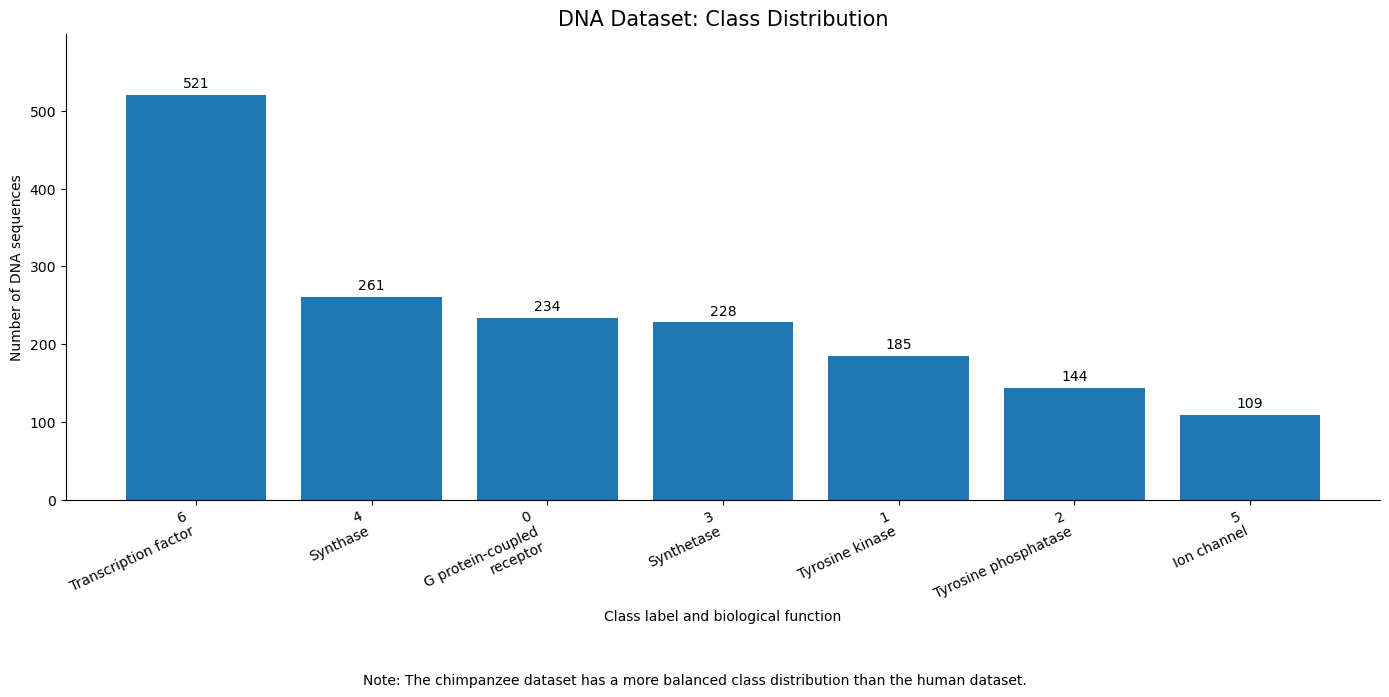

In [33]:
import matplotlib.pyplot as plt
note="Note: The chimpanzee dataset has a more balanced class distribution than the human dataset."
def plot_class_distribution(df,note):
    # Map numeric labels to biological class names
    class_names = {
        0: "G protein-coupled\nreceptor",
        1: "Tyrosine kinase",
        2: "Tyrosine phosphatase",
        3: "Synthetase",
        4: "Synthase",
        5: "Ion channel",
        6: "Transcription factor"
    }

    # Count classes and sort by frequency, highest to lowest
    class_counts = df["class"].value_counts().sort_values(ascending=False)

    # Create labels showing both the numeric class and its name
    x_labels = [
        f"{label}\n{class_names.get(label, 'Unknown class')}"
        for label in class_counts.index
    ]

    # Plot the distribution
    fig, ax = plt.subplots(figsize=(14, 7))
    bars = ax.bar(x_labels, class_counts.values)

    # Display counts above bars
    ax.bar_label(bars, padding=3)

    ax.set_title("DNA Dataset: Class Distribution", fontsize=15)
    ax.set_xlabel("Class label and biological function")
    ax.set_ylabel("Number of DNA sequences")

    # Requested note: verify this comparison against the human dataset
    fig.text(
        0.5, 0.015,
        note,
        ha="center",
        fontsize=10,
        wrap=True
    )

    plt.xticks(rotation=25, ha="right")
    ax.set_ylim(0, class_counts.max() * 1.15)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout(rect=[0, 0.08, 1, 1])
    plt.show()
######
plot_class_distribution(df_Chp,note)

In [34]:
df_Chp.describe(include='all').T#as we have 2 columns:one categorical(object dtype),one numerical(int64)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sequence,1682,1675,ATGCCGAGCTGCTCCACGTCCACCATGCCGGGCATGATCTGCAAGA...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,1682.0,NaN,NaN,NaN,3.491082,2.177486,0.0,2.0,4.0,6.0,6.0


In [40]:
print(df_Chp.duplicated().sum()) #7 duplicates (leave them for now)

7


In [41]:
df_Chp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  1682 non-null   object
 1   class     1682 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 26.4+ KB


In [42]:
# function to convert sequence strings into k-mer words, default size = 6 (hexamer words)
def getKmers(sequence, size=6): #hexamers
    return [sequence[x:x+size].lower() for x in range(len(sequence) - size + 1)]  #-size to stop k-steps from the last idx,and +1 as idx start from zero(range(n)~range(0,n-1)) n-1 +1=n
#########
#add column of the k-mer transformed words and drop the original  sequence column
df_Chp['words']=df_Chp['sequence'].apply(lambda x:getKmers(x)) # x is each value(sequence ) in the sequence column
df_Chp=df_Chp.drop(columns='sequence')

In [43]:
display(df_Chp.head())

,class,words
0,4,"[atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac..."
1,4,"[atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa..."
2,4,"[atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc..."
3,4,"[atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc..."
4,6,"[atgggc, tgggca, gggcag, ggcagc, gcagcg, cagcg..."


In [49]:
Chp_texts=list(df_Chp['words']) #this is a list of list(each list/item represent a row of kmers sequences)
for i in range(len(Chp_texts)):
    Chp_texts[i]=' '.join(Chp_texts[i]) #join the small kmer sequences of each row by a space ' '
y=df_Chp['class'] #0,1,2,3,4,5,6
print(Chp_texts[4])#this is the 4th list of the lists wrapped together that represent the 4th row

atgggc tgggca gggcag ggcagc gcagcg cagcgc agcgcc gcgcca cgccag gccagc ccagcc cagccc agcccg gcccgg cccggg ccgggt cgggtc gggtct ggtctg gtctga tctgag ctgagc tgagca gagcag agcagc gcagcg cagcgt agcgtg gcgtgt cgtgtc gtgtcc tgtccc gtcccc tccccc ccccca ccccag cccagc ccagcc cagcca agccac gccacc ccacct cacctc acctcc cctcct ctcctg tcctgc cctgct ctgctg tgctgc gctgcc ctgccc tgcccc gccccc cccccc cccccg ccccga cccgac ccgaca cgacac gacacg acacgg cacggt acggtg cggtgt ggtgtc gtgtcg tgtcgc gtcgcg tcgcgg cgcgga gcggac cggaca ggacag gacagg acaggc caggct aggctt ggcttg gcttgg cttgga ttggag tggaga ggagaa gagaag agaagg gaaggc aaggcg aggcgg ggcggc gcggca cggcag ggcagc gcagcg cagcgg agcggg gcgggg cggggg gggggc ggggca gggcag ggcagt gcagtg cagtgg agtggg gtgggt tgggtc gggtct ggtctc gtctcg tctcga ctcgag tcgaga cgagag gagaga agagac gagacg agacgg gacggg acggga cgggac gggact ggactg gactgg actgga ctggag tggagt ggagtc gagtcc agtccc gtccca tcccag cccagt ccagtc cagtcc agtcca gtccac tccacc ccaccc cacccg acccgc cccgcc ccgcca

now we will use the loaded trained count_vectorizer and Naives bayes model(fitted/trained on the human datset) and compare metrics

In [46]:
display(df_Chp.head())

,class,words
0,4,"[atgccc, tgcccc, gcccca, ccccaa, cccaac, ccaac..."
1,4,"[atgaac, tgaacg, gaacga, aacgaa, acgaaa, cgaaa..."
2,4,"[atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc..."
3,4,"[atggcc, tggcct, ggcctc, gcctcg, cctcgc, ctcgc..."
4,6,"[atgggc, tgggca, gggcag, ggcagc, gcagcg, cagcg..."


In [51]:
#######
import joblib
# joblib.dump(classifier, "multinomial_naive_bayes_model.pkl")
# joblib.dump(cv, "fitted_count_vectorizer.pkl")
##########
human_cv=joblib.load('fitted_count_vectorizer.pkl')
human_naives_bayes=joblib.load('multinomial_naive_bayes_model.pkl')

In [54]:
# 1. Transform chimpanzee sequences using the fitted human vectorizer
x_Chp = human_cv.transform(Chp_texts)

# 2. Predict classes using the trained human Naive Bayes model
y_pred_Chp = human_naives_bayes.predict(x_Chp)

# 3. Inspect the predictions
print(y_pred_Chp)

[4 4 4 ... 6 3 3]


In [55]:
print("Number of chimpanzee sequences:", len(Chp_texts))
print("Feature matrix shape:", x_Chp.shape)
print("Number of predictions:", len(y_pred_Chp))

Number of chimpanzee sequences: 1682
Feature matrix shape: (1682, 232414)
Number of predictions: 1682


In [56]:
# y=df_Chp['class'] #0,1,2,3,4,5,6
accuracy = accuracy_score(y, y_pred_Chp)
print(f"{accuracy*100:.2f}%")##98.1% accuracy

98.10%


In [62]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
human_trained_model=human_naives_bayes
def evaluate_Chp_by_humanmodel(x_Chp, y, human_trained_model, print_results=True, results_as_df=False):
    # Predict using the already-trained model
    y_pred = model.predict(x)

    # Calculate evaluation metrics
    results = {
        "Accuracy": f"{accuracy_score(y, y_pred) * 100:.2f}%",
        "Precision": f"{precision_score(y, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
        "Recall": f"{recall_score(y, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
        "F1 Score": f"{f1_score(y, y_pred, average='weighted', zero_division=0) * 100:.2f}%"
    }

    if results_as_df:
        results = pd.DataFrame(results.items(), columns=["Metric", "Score"]).set_index("Metric")

    if print_results:
        print(results)

    return results

In [66]:
human_trained_model=human_naives_bayes
evaluate_Chp_by_humanmodel(x_Chp, y, human_trained_model, print_results=0, results_as_df=1)


,Score
Metric,
Accuracy,98.10%
Precision,98.16%
Recall,98.10%
F1 Score,98.10%


now lets make a full pipeline function so we can just provide the dataset,fittedCV and fitted/trained Model(on human data)

In [67]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score)

# 1. Convert a DNA sequence into overlapping k-mers
def getKmers(sequence, size=6):
    return [
        sequence[i:i + size].lower()
        for i in range(len(sequence) - size + 1)
    ]


# 2. Complete evaluation pipeline using the human-trained model
def evaluate_by_human_model(
    df,
    human_model,
    human_cv,
    print_results=True,
    results_as_df=False
):
    df = df.copy()

    # Generate k-mers from each DNA sequence
    df["words"] = df["sequence"].apply(lambda seq: getKmers(seq, 6))

    # Join each sequence's k-mers with spaces
    texts = df["words"].apply(lambda kmers: " ".join(kmers))

    # Extract the actual class labels
    y_true = df["class"]

    # Transform using the original fitted human vectorizer
    X = human_cv.transform(texts)

    # Predict using the original trained human model
    y_pred = human_model.predict(X)

    # Calculate evaluation metrics
    results = {
        "Accuracy": f"{accuracy_score(y_true, y_pred) * 100:.2f}%",
        "Precision": f"{precision_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
        "Recall": f"{recall_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
        "F1 Score": f"{f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100:.2f}%"
    }

    # Optionally return results as a DataFrame
    if results_as_df:
        results = pd.DataFrame(
            results.items(),
            columns=["Metric", "Score"]
        ).set_index("Metric")

    if print_results:
        print(results)

    return results

In [79]:
org_df_Chp=pd.read_table(r'chimp_data.txt')
import joblib
human_cv=joblib.load('fitted_count_vectorizer.pkl')
human_naives_bayes=joblib.load('multinomial_naive_bayes_model.pkl')
Chp_res_by_human_trained_model=evaluate_by_human_model(
    org_df_Chp,
    human_naives_bayes,
    human_cv,
    print_results=0,
    results_as_df=1)
####



In [80]:
Chp_res_by_human_trained_model

,Score
Metric,
Accuracy,98.10%
Precision,98.16%
Recall,98.10%
F1 Score,98.10%


as we can see the scores are high suggesting the high similarity between the Chimp.and Human dna sequences,so similar that the scores are as if the model was tested against data that the model has almost seen like before
for a fair comparison we will apply the same pipeline to the original human dataset ;this will obvioulsy result in even higher scores as this is the data that the model used to train and learn(the 70% train data of human dataset)

In [84]:
org_human_data=pd.read_table(r'2human_data.txt')
import joblib
human_cv=joblib.load('fitted_count_vectorizer.pkl')
human_naives_bayes=joblib.load('multinomial_naive_bayes_model.pkl')
human_seen_and_unseen_results=evaluate_by_human_model(
    org_human_data,
    human_naives_bayes,
    human_cv,
    print_results=0,
    results_as_df=1)
####

In [85]:
human_seen_and_unseen_results

,Score
Metric,
Accuracy,99.22%
Precision,99.23%
Recall,99.22%
F1 Score,99.22%


obviously the scores are higher here as 70% of the human dataset(70-30 split) was the data that the loaded model used to train and learn

### Dog Data

In [71]:
df_dog=pd.read_table('dog_data.txt')

In [74]:
print(f"shape:{df_dog.shape}")#shape:(820, 2)
print("duplicates:",df_dog.duplicated().sum())
print(df_dog.info())
display(df_dog.head())

shape:(820, 2)
duplicates: 3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   sequence  820 non-null    object
 1   class     820 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 12.9+ KB
None


,sequence,class
0,ATGCCACAGCTAGATACATCCACCTGATTTATTATAATCTTTTCAA...,4
1,ATGAACGAAAATCTATTCGCTTCTTTCGCTGCCCCCTCAATAATAG...,4
2,ATGGAAACACCCTTCTACGGCGATGAGGCGCTGAGCGGCCTGGGCG...,6
3,ATGTGCACTAAAATGGAACAGCCCTTCTACCACGACGACTCATACG...,6
4,ATGAGCCGGCAGCTAAACAGAAGCCAGAACTGCTCCTTCAGTGACG...,0


In [77]:
org_df_dog=pd.read_table('dog_data.txt')
import joblib
human_cv=joblib.load('fitted_count_vectorizer.pkl')
human_naives_bayes=joblib.load('multinomial_naive_bayes_model.pkl')
dog_res_by_human_trained_model=evaluate_by_human_model(
    org_df_dog,
    human_naives_bayes,
    human_cv,
    print_results=0,
    results_as_df=1)
####

In [78]:
dog_res_by_human_trained_model

,Score
Metric,
Accuracy,90.49%
Precision,91.98%
Recall,90.49%
F1 Score,90.44%


---
-------


# Cross-Species Evaluation of a Human-Trained DNA Classification Model

## 1. Human Model Performance on the Held-Out Test Set

The human dataset was divided into training and testing sets using a 70:30 split. The models were trained on 70% of the human data and evaluated on the remaining 30%, which was not used during training.

| Model | Accuracy | Precision | Recall | F1 Score |
|---|---:|---:|---:|---:|
| Logistic Regression | 93.00% | 93.93% | 93.00% | 93.07% |
| Multinomial Naive Bayes | 97.56% | 97.64% | 97.56% | 97.57% |

**Interpretation:** Multinomial Naive Bayes achieved higher performance than Logistic Regression across all four metrics on the held-out human test set. Its accuracy of 97.56% indicates that the model classified most unseen human sequences correctly.

## 2. Human Model Performance on the Entire Human Dataset

The trained Multinomial Naive Bayes model was evaluated on the entire human dataset, including both the 70% training subset and the 30% held-out test subset.

| Metric | Score |
|---|---:|
| Accuracy | 99.22% |
| Precision | 99.23% |
| Recall | 99.22% |
| F1 Score | 99.22% |

**Interpretation:** Performance increased from 97.56% accuracy on the held-out test set to 99.22% on the entire human dataset. This increase is expected because the full dataset includes the training sequences that the model has already seen. Therefore, the 99.22% result should not be interpreted as an independent estimate of generalization performance. The held-out test result is the more appropriate human benchmark.

## 3. Human-Trained Model Performance on the Chimpanzee Dataset

The same human-trained Multinomial Naive Bayes model and fitted CountVectorizer were applied to the entire chimpanzee dataset without retraining or fitting the vectorizer again.

| Metric | Score |
|---|---:|
| Accuracy | 98.10% |
| Precision | 98.16% |
| Recall | 98.10% |
| F1 Score | 98.10% |

**Interpretation:** The model achieved 98.10% accuracy on the chimpanzee dataset. This is a strong cross-species classification result and is close to the 97.56% accuracy obtained on the held-out human test set. It suggests that the DNA sequence patterns learned from human genes are highly transferable to the chimpanzee sequences in this dataset.

## 4. Human-Trained Model Performance on the Dog Dataset

The same human-trained model and fitted CountVectorizer were applied to the entire dog dataset, again without retraining.

| Metric | Score |
|---|---:|
| Accuracy | 90.49% |
| Precision | 91.98% |
| Recall | 90.49% |
| F1 Score | 90.44% |

**Interpretation:** The model achieved 90.49% accuracy on the dog dataset, which is lower than its performance on both the chimpanzee dataset and the held-out human test set. This suggests that the learned human DNA sequence patterns transfer less effectively to the dog sequences in this dataset. The difference may reflect species-specific sequence composition, differences in gene representation, dataset quality, class distribution, or the degree of sequence similarity between the datasets.

## 5. Overall Conclusion

The human-trained Multinomial Naive Bayes model performed best on the entire human dataset (99.22%), followed by the chimpanzee dataset (98.10%) and the dog dataset (90.49%). However, the full-human-dataset score includes the training examples and is therefore not directly comparable to independent evaluation scores.

The more appropriate comparison is between the held-out human test accuracy (97.56%), chimpanzee accuracy (98.10%), and dog accuracy (90.49%). The chimpanzee result is close to the human test result, whereas the dog result is lower by 7.07 percentage points relative to the human test accuracy.

These findings suggest that the sequence features learned from human DNA generalize more effectively to the chimpanzee dataset than to the dog dataset. This pattern is consistent with the closer evolutionary relationship between humans and chimpanzees. Nevertheless, classification performance alone does not establish evolutionary distance or prove that evolutionary relatedness is the sole cause of the difference.

Further validation should include class-wise precision and recall, confusion matrices, verification of consistent class definitions, and checks for duplicate or highly similar sequences across datasets. A more rigorous assessment could also use sequence-similarity-aware splitting to reduce the risk of overly optimistic results.


# Remaining work:split each dataset and train a scratch model against them and then compare the results with the human_results after 70-30 split
lets make a function that encapsulates our pipeline

In [86]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# 1. Convert a DNA sequence into overlapping k-mers
def getKmers(sequence, size=6):
    sequence = sequence.strip().upper()

    return [
        sequence[i:i + size].lower()
        for i in range(len(sequence) - size + 1)
    ]


# 2. Complete training and evaluation pipeline
def evaluate_models(
    df,
    print_results=True,
    results_as_df=False,
    return_models=False
):
    # Work on a copy to preserve the original DataFrame
    data = df.copy()

    # Generate space-separated k-mer text from DNA sequences
    texts = data["sequence"].apply(
        lambda seq: " ".join(getKmers(seq, size=6))
    )

    # Actual class labels
    y = data["class"]

    # Split raw text BEFORE fitting the vectorizer
    text_train, text_test, y_train, y_test = train_test_split(
        texts,
        y,
        test_size=0.3,
        stratify=y,
        random_state=42
    )

    # Learn the vocabulary from training data only
    cv = CountVectorizer(ngram_range=(4, 4))

    x_train = cv.fit_transform(text_train)
    x_test = cv.transform(text_test)

    # Define the models
    models = {
        "Logistic Regression": LogisticRegression(random_state=42),
        "Multinomial Naive Bayes": MultinomialNB(alpha=0.1)
    }

    results = {}
    trained_models = {}

    # Train and evaluate each model
    for name, model in models.items():

        model.fit(x_train, y_train)

        y_pred = model.predict(x_test)

        results[name] = {
            "Accuracy": f"{accuracy_score(y_test, y_pred) * 100:.2f}%",
            "Precision": f"{precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
            "Recall": f"{recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%",
            "F1 Score": f"{f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100:.2f}%"
        }

        trained_models[name] = model

    # Format results
    if results_as_df:
        results = pd.DataFrame(results).T

    if print_results:
        print(results)

    # Optionally return trained objects for reuse
    if return_models:
        return results, cv, trained_models

    return results


In [90]:
org_human_df=pd.read_table(r'human_data.txt')
org_Chp_df=pd.read_table(r'chimp_data.txt')
org_dog_df=pd.read_table(r'dog_data.txt')

# Final Human Results(with 70-30 splitting before both CV and Model training)

In [91]:
f_human_res=evaluate_models(
    org_human_df,
    print_results=0,
    results_as_df=1,
    return_models=False
)

In [92]:
f_human_res

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,93.00%,93.93%,93.00%,93.07%
Multinomial Naive Bayes,97.49%,97.59%,97.49%,97.50%


-----------

# Final Chimpanze Results(with 70-30 splitting before both CV and Model training)

In [93]:
f_Chp_res=evaluate_models(
    org_Chp_df,
    print_results=0,
    results_as_df=1,
    return_models=False
)

In [94]:
f_Chp_res

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,86.14%,89.13%,86.14%,86.40%
Multinomial Naive Bayes,89.70%,91.60%,89.70%,89.87%


## obviously this time the results were quite a bit lower as these results reflect the model trainig on only 70% of the Chimp.data and beeing teste on the unseen 30%
while the previous results were using the same pretrained model on human data and just testing it against the whole Chimp.data which has similarities ot the human data(pseudo data leakage)
this migh imply that other model params or maybe another model will be better at predicting Chimp.DNA seq.
but the close results in the 1st and 2nd experiments prove the relative homogenicity between the human and Chimpanze data

`Interpretation: Multinomial Naive Bayes achieved 89.70% accuracy, outperforming Logistic Regression by 3.56 percentage points. This is lower than the human result, suggesting that classification difficulty differs between the datasets. It does not, by itself, establish that chimpanzee DNA is less similar to human DNA.`

-----------

# Final Dog Results(with 70-30 splitting before both CV and Model training)

In [96]:
f_dog_res=evaluate_models(
    org_dog_df,
    print_results=0,
    results_as_df=1,
    return_models=False
)

In [97]:
f_dog_res

,Accuracy,Precision,Recall,F1 Score
Logistic Regression,56.50%,77.25%,56.50%,53.90%
Multinomial Naive Bayes,60.16%,75.00%,60.16%,57.53%


`Interpretation: Both models performed substantially worse on the dog dataset, with Multinomial Naive Bayes achieving 60.16% accuracy.
The relatively high weighted precision compared with accuracy and F1 score suggests that errors may differ across classes, although a confusion matrix and per-class metrics are needed to determine the cause.`

The results support three observations:
1. Human: The model classifies human sequences very accurately.
2. Chimpanzee: Performance remains relatively high, although it is 7.79 percentage points below human performance.
3. Dog: Performance falls substantially, with accuracy 29.54 percentage points below the chimpanzee result.
This pattern is consistent with the closer evolutionary relationship between humans and chimpanzees. However, within-species classification accuracy is not a direct measure of evolutionary similarity. The species may differ in dataset quality, class distribution, sequence lengths, gene representation and the difficulty of distinguishing their classes.